# SMS Spam Classifier — Improved Evaluation

This notebook trains a Multinomial Naive Bayes classifier to distinguish **ham** (legitimate) SMS messages from **spam** messages.


## 1. Import the libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

import pickle

## 2. Load and inspect the dataset

In [2]:
# Download the SMS Spam Collection dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(
    url,
    sep="\\t",
    header=None,
    names=["label", "message"]
)

# Inspect a few records
display(df.head())

# Check dataset size and missing values
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

# Count the messages in each class
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nClass distribution (percentage):")
print((df["label"].value_counts(normalize=True) * 100).round(2))

/tmp/ipykernel_968/1851185262.py:4: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dataset shape: (5574, 2)

Missing values:
label      0
message    0
dtype: int64

Class distribution:
label
ham     4827
spam     747
Name: count, dtype: int64

Class distribution (percentage):
label
ham     86.6
spam    13.4
Name: proportion, dtype: float64


## 3. Separate features and labels

- `X` contains the SMS message text.
- `y` contains the correct class label (`ham` or `spam`).

In [3]:
X = df["message"]
y = df["label"]

## 4. Split the data using stratification

We reserve 20% of the data for testing. `stratify=y` preserves approximately the same ham/spam proportions in both the training and test sets.

`random_state=1` makes the split reproducible.

In [4]:
# First, separate the test set (15%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=1,
    stratify=y
)

# Next, separate training (70%) and validation (15%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1765,
    random_state=1,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("Training set size:", len(X_train))
print("Testing set size:", len(X_test))

print("\nTraining-set class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTest-set class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 3900
Validation samples: 837
Test samples: 837
Training set size: 3900
Testing set size: 837

Training-set class proportions:
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64

Test-set class proportions:
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


## 5. Convert text into numerical features with TF-IDF

A machine learning model cannot directly learn from raw text. TF-IDF converts each message into a numerical feature vector.

**Important:** fit the vectorizer on the training messages only. Then use the fitted vectorizer to transform the test messages. This prevents information from the test set from influencing the learned vocabulary and IDF weights.

In [5]:
# Initialize the TF-IDF vectorizer
vectorizer = TfidfVectorizer()

# Convert messages into numerical features
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)
X_test_vec = vectorizer.transform(X_test)

# Display feature matrix dimensions
print("Training matrix:", X_train_vec.shape)
print("Validation matrix:", X_val_vec.shape)
print("Testing matrix:", X_test_vec.shape)
print("Testing feature matrix:", X_test_vec.shape)

Training matrix: (3900, 7145)
Validation matrix: (837, 7145)
Testing matrix: (837, 7145)
Testing feature matrix: (837, 7145)


## 6. Train the Multinomial Naive Bayes model

In [6]:
# Initialize the Naive Bayes model
model = MultinomialNB()

# Train the model using training data
model.fit(X_train_vec, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [7]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Get the probability that each validation message is spam
spam_index = list(model.classes_).index("spam")

spam_probabilities = model.predict_proba(X_val_vec)[:, spam_index]

# Test different classification thresholds
thresholds = [0.5, 0.4, 0.3, 0.2]

for threshold in thresholds:

    predictions = np.where(
        spam_probabilities >= threshold,
        "spam",
        "ham"
    )

    precision = precision_score(
        y_val, predictions, pos_label="spam"
    )

    recall = recall_score(
        y_val, predictions, pos_label="spam"
    )

    f1 = f1_score(
        y_val, predictions, pos_label="spam"
    )

    print(f"\nThreshold: {threshold}")
    print(f"Spam Precision: {precision:.4f}")
    print(f"Spam Recall: {recall:.4f}")
    print(f"Spam F1-score: {f1:.4f}")


Threshold: 0.5
Spam Precision: 1.0000
Spam Recall: 0.6786
Spam F1-score: 0.8085

Threshold: 0.4
Spam Precision: 0.9884
Spam Recall: 0.7589
Spam F1-score: 0.8586

Threshold: 0.3
Spam Precision: 0.9889
Spam Recall: 0.7946
Spam F1-score: 0.8812

Threshold: 0.2
Spam Precision: 0.9697
Spam Recall: 0.8571
Spam F1-score: 0.9100


Final Test Results (Threshold = 0.20)
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       725
        spam       1.00      0.84      0.91       112

    accuracy                           0.98       837
   macro avg       0.99      0.92      0.95       837
weighted avg       0.98      0.98      0.98       837



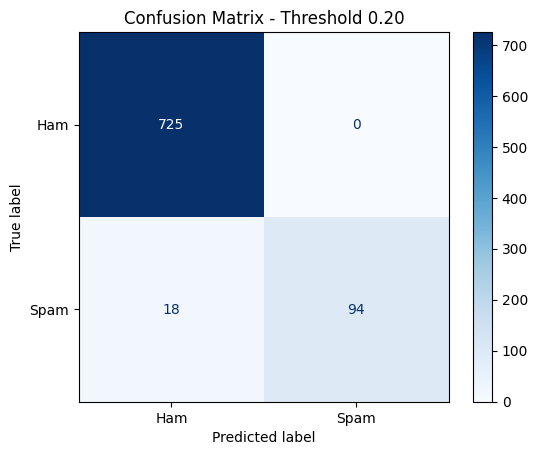

In [8]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Get spam probabilities for the test messages
spam_probabilities_test = model.predict_proba(X_test_vec)[:, spam_index]

# Apply our selected threshold
final_predictions = np.where(
    spam_probabilities_test >= 0.20,
    "spam",
    "ham"
)

# Display classification report
print("Final Test Results (Threshold = 0.20)")
print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))

# Display confusion matrix
cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=["ham", "spam"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Threshold 0.20")
plt.show()

## 7. Evaluate the model

We report several metrics because the dataset contains many more ham messages than spam messages.

- **Accuracy:** proportion of all predictions that are correct.
- **Precision (spam):** among messages predicted as spam, the proportion that really are spam.
- **Recall (spam):** among all actual spam messages, the proportion detected by the model.
- **F1-score (spam):** harmonic mean of spam precision and spam recall.

In [9]:
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Get spam probabilities for test messages
spam_index = list(model.classes_).index("spam")

spam_probabilities = model.predict_proba(X_test_vec)[:, spam_index]

# Apply the selected threshold
best_threshold = 0.20

y_pred = np.where(
    spam_probabilities >= best_threshold,
    "spam",
    "ham"
)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Selected Threshold: {best_threshold}")
print(f"Accuracy: {accuracy * 100:.2f}%")

# Generate classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    target_names=["Ham", "Spam"],
    digits=4,
    zero_division=0
))

Selected Threshold: 0.2
Accuracy: 97.85%

Classification Report:
              precision    recall  f1-score   support

         Ham     0.9758    1.0000    0.9877       725
        Spam     1.0000    0.8393    0.9126       112

    accuracy                         0.9785       837
   macro avg     0.9879    0.9196    0.9502       837
weighted avg     0.9790    0.9785    0.9777       837



## 8. Visualise the confusion matrix

The confusion matrix shows the number of correct and incorrect predictions for each class. With scikit-learn's display, rows represent the true labels and columns represent the predicted labels.

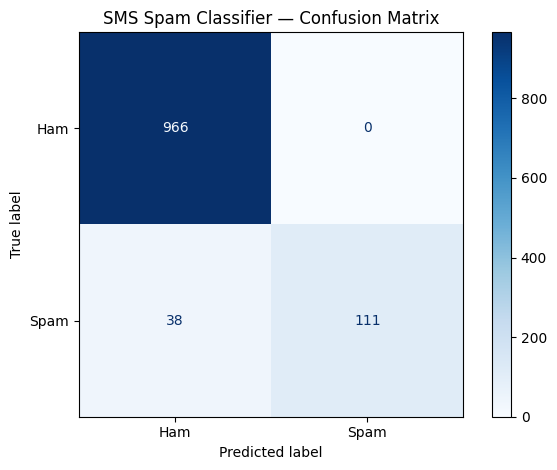

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    display_labels=["Ham", "Spam"],
    cmap="Blues",
    values_format="d"
)

plt.title("SMS Spam Classifier — Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Save the trained model and TF-IDF vectorizer

The model and vectorizer must be used together during inference. The vectorizer converts incoming text into the feature representation expected by the trained model.

In [ ]:
# Save the model
with open("spam_model.pkl", "wb") as file:
    pickle.dump(model, file)

# Save the fitted vectorizer
with open("vectorizer.pkl", "wb") as file:
    pickle.dump(vectorizer, file)

print("Model and vectorizer saved successfully.")

Model and vectorizer saved successfully.


## 10. Test the saved artifacts with a new message

This small check confirms that the saved files can be loaded and used for a prediction in the current runtime.

In [ ]:
# Load the saved model and vectorizer
with open("spam_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

with open("vectorizer.pkl", "rb") as file:
    loaded_vectorizer = pickle.load(file)

# Enter a sample message
sample_message = ["Congratulations! You have won a free prize. Call now!"]

sample_features = loaded_vectorizer.transform(sample_message)
sample_prediction = loaded_model.predict(sample_features)[0]

print("Message:", sample_message[0])
print("Prediction:", sample_prediction)

Message: Congratulations! You have won a free prize. Call now!
Prediction: spam


In [ ]:
import pickle

# Save the improved Naive Bayes model
with open("spam_model.pkl", "wb") as file:
    pickle.dump(model, file)

# Save the updated TF-IDF vectorizer
with open("vectorizer.pkl", "wb") as file:
    pickle.dump(vectorizer, file)

# Save the selected classification threshold
with open("threshold.pkl", "wb") as file:
    pickle.dump(0.20, file)

print("Improved model saved successfully!")

Improved model saved successfully!


In [ ]:
import os

for filename in ["spam_model.pkl", "vectorizer.pkl", "threshold.pkl"]:
    print(filename, ":", os.path.exists(filename))

spam_model.pkl : True
vectorizer.pkl : True
threshold.pkl : True


In [ ]:
from google.colab import files

files.download("spam_model.pkl")
files.download("vectorizer.pkl")
files.download("threshold.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn
import numpy as np

print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
import sys
print(sys.version)

Scikit-learn: 1.6.1
NumPy: 2.4.6
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [10]:
import os

print("Current directory:", os.getcwd())
print("Tracker file exists:", os.path.exists("experiment_tracker.py"))

Current directory: /content
Tracker file exists: False


In [11]:
import os

os.chdir("/content/spam-classifier")

print("Current directory:", os.getcwd())
print("Tracker file exists:", os.path.exists("experiment_tracker.py"))

FileNotFoundError: [Errno 2] No such file or directory: '/content/spam-classifier'

In [12]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [13]:
!git clone https://github.com/KhaleelOnoruoiza/spam-classifier.git

Cloning into 'spam-classifier'...
remote: Enumerating objects: 121, done.
remote: Counting objects: 100% (121/121), done.
remote: Compressing objects: 100% (107/107), done.
remote: Total 121 (delta 47), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (121/121), 383.36 KiB | 2.88 MiB/s, done.
Resolving deltas: 100% (47/47), done.


In [14]:
import os

os.chdir("/content/spam-classifier")

print("Current directory:", os.getcwd())
print("Tracker file exists:", os.path.exists("experiment_tracker.py"))

Current directory: /content/spam-classifier
Tracker file exists: True


In [15]:
from experiment_tracker import log_experiment

print("Experiment tracker imported successfully!")

Experiment tracker imported successfully!


In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate metrics for the Spam class
spam_precision = precision_score(
    y_test, y_pred, pos_label="spam"
)

spam_recall = recall_score(
    y_test, y_pred, pos_label="spam"
)

spam_f1 = f1_score(
    y_test, y_pred, pos_label="spam"
)

# Record the experiment
log_experiment(
    model="Multinomial Naive Bayes",
    feature_extraction="TF-IDF",
    train_test_split="70/15/15",
    threshold=best_threshold,
    accuracy=accuracy,
    precision=spam_precision,
    recall=spam_recall,
    f1_score=spam_f1,
    notes="Validation-selected threshold; evaluated on held-out test set"
)

Experiment EXP20261107205957 recorded successfully.


In [17]:
import pandas as pd

experiment_log = pd.read_csv("experiment_log.csv")

experiment_log.tail()

,experiment_id,date,model,feature_extraction,train_test_split,threshold,accuracy,precision,recall,f1_score,notes
0,EXP001,Not recorded,Multinomial Naive Bayes,TF-IDF,80/20,0.5,0.965900,1.0,0.745000,0.853800,Original baseline model
1,EXP002,Not recorded,Multinomial Naive Bayes,TF-IDF,70/15/15,0.2,0.980000,1.0,0.840000,0.910000,Improved model with validation-based threshold...
2,EXP20261107205957,2026-11-07 20:59:57,Multinomial Naive Bayes,TF-IDF,70/15/15,0.2,0.978495,1.0,0.839286,0.912621,Validation-selected threshold; evaluated on he...


In [20]:
!git status --short

?? __pycache__/


In [21]:
!git restore experiment_log.csv

In [22]:
!git pull origin main

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 6 (delta 4), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 2.39 KiB | 306.00 KiB/s, done.
From https://github.com/KhaleelOnoruoiza/spam-classifier
 * branch            main       -> FETCH_HEAD
   6a01d12..0cc0870  main       -> origin/main
Updating 6a01d12..0cc0870
Fast-forward
 experiment_log.csv    |  1 +
 experiment_tracker.py | 26 ++++++++++++++++++++------
 2 files changed, 21 insertions(+), 6 deletions(-)


In [23]:
import importlib
import experiment_tracker

importlib.reload(experiment_tracker)

from experiment_tracker import log_experiment

print("Updated experiment tracker loaded successfully!")

Updated experiment tracker loaded successfully!


In [24]:
import csv
from pathlib import Path

with open("experiment_log.csv", "r", newline="", encoding="utf-8") as file:
    reader = csv.DictReader(file)
    existing_ids = [row["experiment_id"] for row in reader]

numbers = [
    int(exp_id.replace("EXP", ""))
    for exp_id in existing_ids
    if exp_id.startswith("EXP") and exp_id.replace("EXP", "").isdigit()
]

next_id = f"EXP{max(numbers, default=0) + 1:03d}"

print("Existing experiments:", existing_ids)
print("Next experiment ID:", next_id)

Existing experiments: ['EXP001', 'EXP002', 'EXP003']
Next experiment ID: EXP004


In [25]:
!ls -1 *.ipynb

Spam_Classifier.ipynb
